In [3]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

c:\Users\HP\numpy\diabetes-prediction


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.preprocessing.data_loader import load_data 
df=load_data()
print("==================sample data=========================")
print(df.head())


==================sample data=========================
     id   chol  stab.glu   hdl  ratio  glyhb    location  age  gender  height  \
0  1000  203.0        82  56.0    3.6   4.31  Buckingham   46  female    62.0   
1  1001  165.0        97  24.0    6.9   4.44  Buckingham   29  female    64.0   
2  1002  228.0        92  37.0    6.2   4.64  Buckingham   58  female    61.0   
3  1003   78.0        93  12.0    6.5   4.63  Buckingham   67    male    67.0   
4  1005  249.0        90  28.0    8.9   7.72  Buckingham   64    male    68.0   

   weight   frame  bp.1s  bp.1d  bp.2s  bp.2d  waist   hip  time.ppn  
0   121.0  medium  118.0   59.0    NaN    NaN   29.0  38.0     720.0  
1   218.0   large  112.0   68.0    NaN    NaN   46.0  48.0     360.0  
2   256.0   large  190.0   92.0  185.0   92.0   49.0  57.0     180.0  
3   119.0   large  110.0   50.0    NaN    NaN   33.0  38.0     480.0  
4   183.0  medium  138.0   80.0    NaN    NaN   44.0  41.0     300.0  


In [10]:
print("==============number of rows and columns===================")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

==============number of rows and columns===================
Number of rows: 403
Number of columns: 19


In [11]:
print("feature name")
print(df.columns)

feature name
Index(['id', 'chol', 'stab.glu', 'hdl', 'ratio', 'glyhb', 'location', 'age',
       'gender', 'height', 'weight', 'frame', 'bp.1s', 'bp.1d', 'bp.2s',
       'bp.2d', 'waist', 'hip', 'time.ppn'],
      dtype='str')


In [13]:
print("==========data type  and statics===============")
print(df.info())
print("=======================data stastics====================")
print(df.describe())

==========data type  and statics===============
<class 'pandas.DataFrame'>
RangeIndex: 403 entries, 0 to 402
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        403 non-null    int64  
 1   chol      402 non-null    float64
 2   stab.glu  403 non-null    int64  
 3   hdl       402 non-null    float64
 4   ratio     402 non-null    float64
 5   glyhb     390 non-null    float64
 6   location  403 non-null    str    
 7   age       403 non-null    int64  
 8   gender    403 non-null    str    
 9   height    398 non-null    float64
 10  weight    402 non-null    float64
 11  frame     391 non-null    str    
 12  bp.1s     398 non-null    float64
 13  bp.1d     398 non-null    float64
 14  bp.2s     141 non-null    float64
 15  bp.2d     141 non-null    float64
 16  waist     401 non-null    float64
 17  hip       401 non-null    float64
 18  time.ppn  400 non-null    float64
dtypes: float64(13), int64(3), str(3)
m

# Data Understanding and EDA

## 1. Dataset Information — `df.info()`

- The dataset contains **403 records and 19 columns**.
- It has 13 numerical decimal columns, 3 integer columns, and 3 categorical columns.
- Some columns contain missing values.
- `bp.2s` and `bp.2d` have only 141 available values each.

### Problems Identified
- Missing values exist in several columns.
- Numerical and categorical features require different preprocessing methods.
- Some columns have a large number of missing values.

### Possible Solutions
- Investigate missing values before selecting an imputation or removal strategy.
- Use numerical and categorical preprocessing techniques separately.

## 2. Descriptive Statistics — `df.describe()`

- The average GlyHb (`glyhb`) is approximately **5.59**.
- GlyHb ranges from **2.68 to 16.11**.
- Some features have unusually high maximum values.
- Numerical features have different measurement ranges.

### Problems Identified
- Possible outliers exist in some numerical features.
- Some features may have different scales.
- The `glyhb` target has only 390 available values.

### Possible Solutions
- Use boxplots and histograms to investigate possible outliers.
- Apply feature scaling where required by the selected algorithms.
- Exclude records with missing `glyhb` from regression training.

In [14]:

missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
bp.2d,262,65.01
bp.2s,262,65.01
glyhb,13,3.23
frame,12,2.98
bp.1s,5,1.24
bp.1d,5,1.24
height,5,1.24
time.ppn,3,0.74
waist,2,0.50
hip,2,0.50


# Missing Value Analysis

## Findings
- `bp.2s` and `bp.2d` have 65.01% missing values each.
- `glyhb` has 3.23% missing values.
- `frame` has 2.98% missing values.
- Other incomplete columns have less than 1.25% missing values.

## Problems
- High missing percentages in the second blood pressure measurements.
- Missing target values in `glyhb`.
- Incomplete numerical and categorical features.

## Possible Solutions
- Investigate and evaluate `bp.2s` and `bp.2d` before deciding whether to retain them.
- Exclude missing `glyhb` targets from regression training.
- Use median imputation for numerical features.
- Use most-frequent imputation for categorical features.

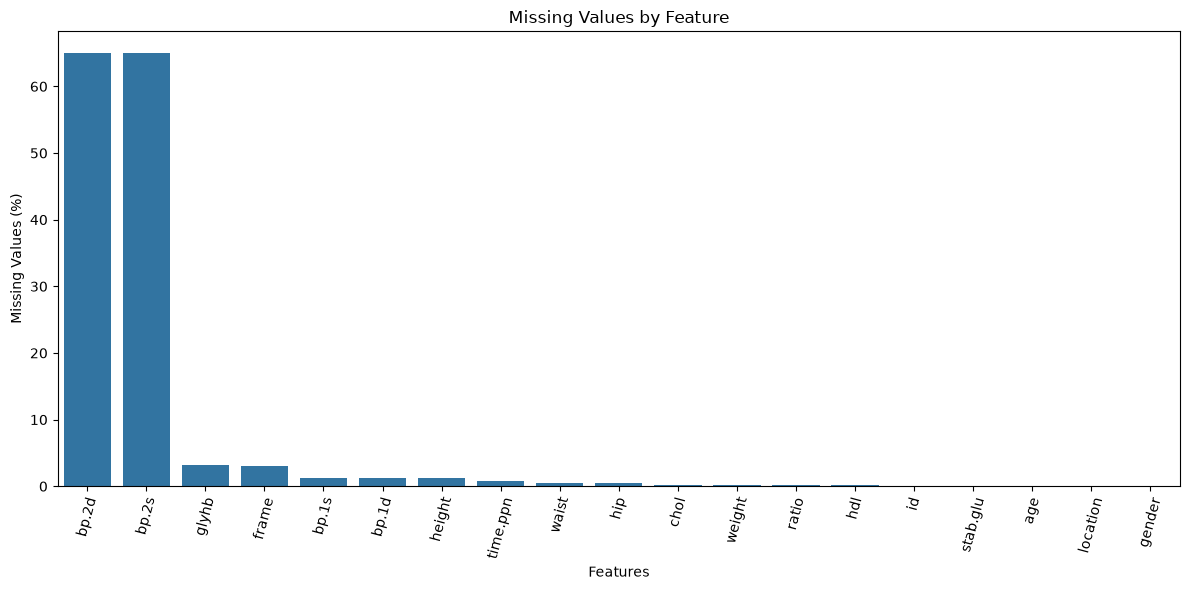

In [15]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing.index,
    y=missing["Missing_Percentage"]
)

plt.xticks(rotation=75)
plt.ylabel("Missing Values (%)")
plt.xlabel("Features")
plt.title("Missing Values by Feature")
plt.tight_layout()
plt.show()

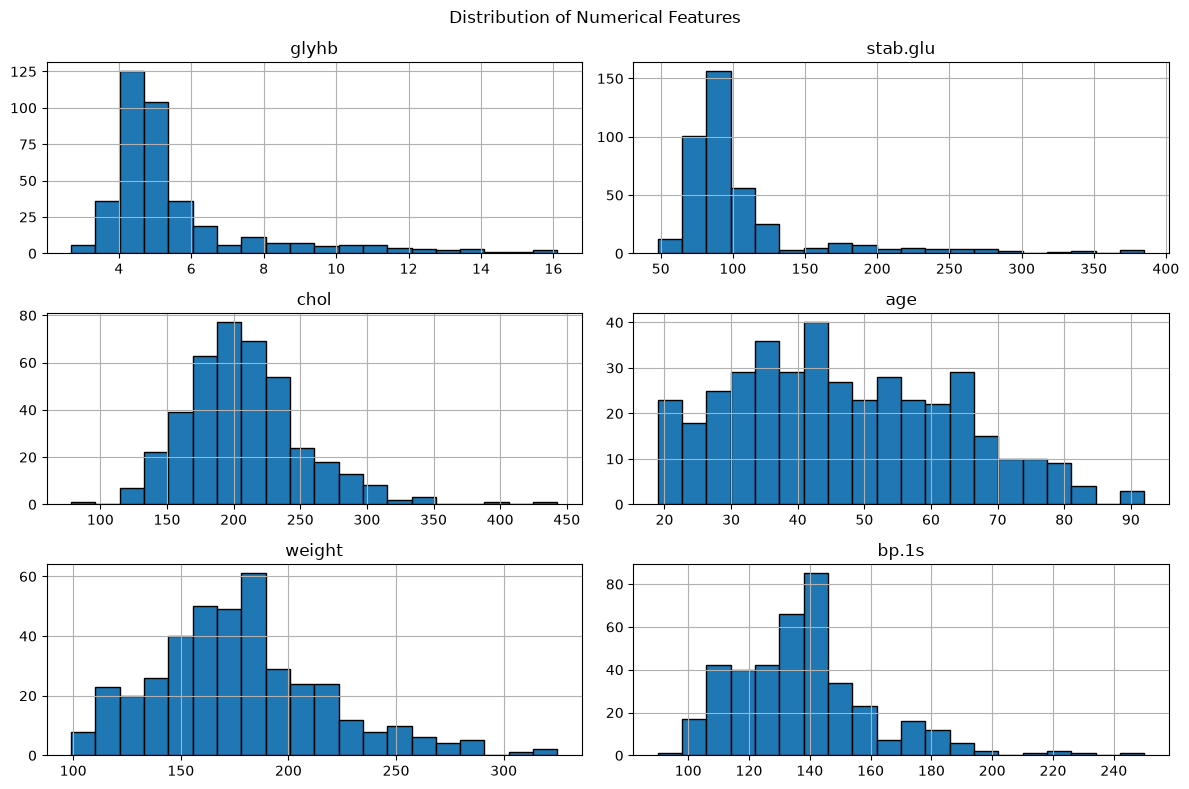

In [16]:

features = [
    "glyhb", "stab.glu", "chol",
    "age", "weight", "bp.1s"
]

df[features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

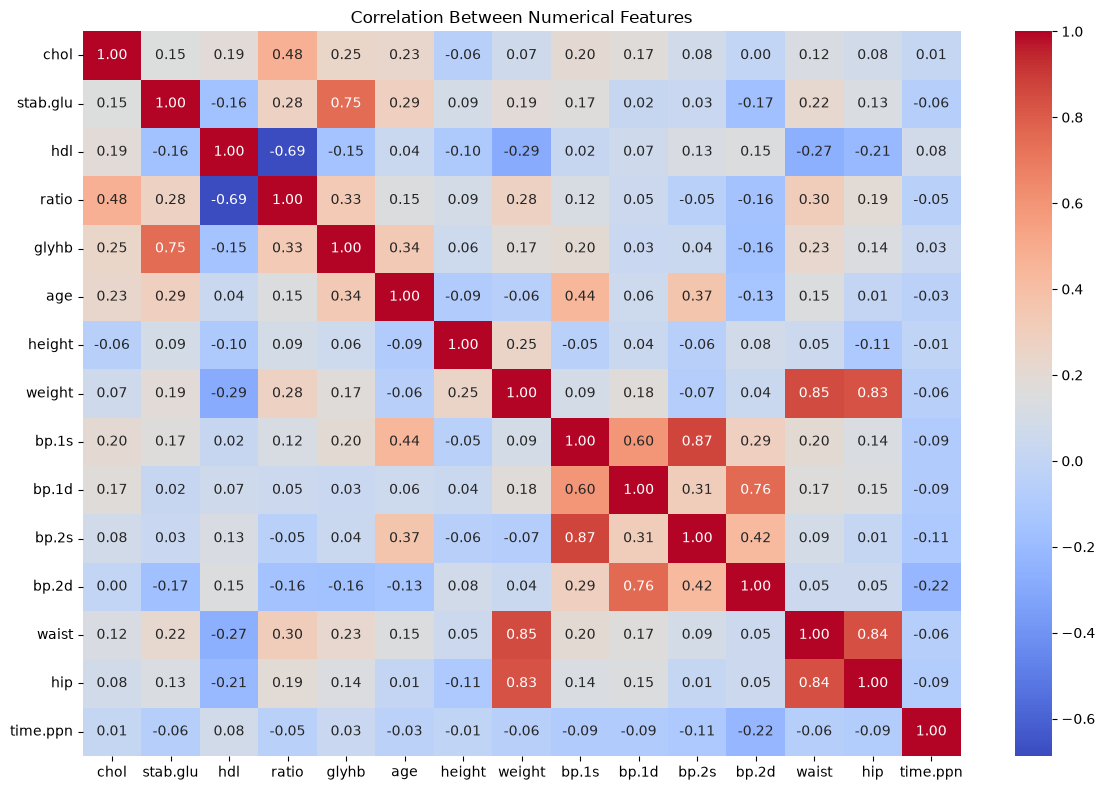

In [5]:
# Correlation analysis

numeric_df = df.select_dtypes(include="number").drop(columns=["id"])

corr = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

# Correlation Analysis

## 1. Findings

Correlation analysis helps us understand how numerical features are related to each other and to our target variable, `glyhb`.

### Relationship with GlyHb

- **`stab.glu` (0.75):** Has the strongest positive relationship with GlyHb. This means patients with higher stabilized glucose values tend to have higher GlyHb values. It is an important feature to investigate for GlyHb prediction.

- **`age` (0.34):** Shows a moderate positive relationship with GlyHb. In this dataset, higher age values tend to be associated with higher GlyHb values.

- **`ratio` (0.33):** Shows a moderate positive relationship with GlyHb. Higher cholesterol ratios tend to be associated with higher GlyHb values.

- **`chol` (0.25), `waist` (0.23), and `bp.1s` (0.20):** Show weak positive relationships with GlyHb.

- **`hdl` (-0.15):** Shows a weak negative relationship. Higher HDL values tend to be associated with slightly lower GlyHb values.

### Relationships Between Input Features

Some input features are also strongly related to each other:

- `weight` and `waist` (0.85): Higher weight tends to be associated with larger waist measurements.
- `waist` and `hip` (0.84): Waist and hip measurements tend to increase together.
- `weight` and `hip` (0.83): Higher weight tends to be associated with larger hip measurements.
- `bp.1s` and `bp.2s` (0.87): The two systolic blood pressure measurements have a strong positive relationship.
- `bp.1d` and `bp.2d` (0.76): The two diastolic blood pressure measurements also have a strong positive relationship.

## 2. Problems Identified

- Some features contain overlapping information because they are strongly correlated with each other.
- `stab.glu` has a much stronger relationship with GlyHb than most other numerical features.
- Correlation only describes linear relationships and does not prove that one feature causes changes in another.

## 3. Decision

- Give particular attention to `stab.glu` because of its strong relationship with GlyHb.
- Keep `age`, `ratio`, `chol`, `waist`, and blood pressure measurements as potential predictors for further investigation.
- Investigate highly correlated features during model development to determine whether they provide useful additional information.
- Do not remove features based only on their correlation values. Evaluate their actual contribution to model performance.

**Conclusion:** The correlation analysis gives us an initial understanding of the features associated with GlyHb and helps guide our feature investigation before model training.

# Feature Engineering Investigation

## Measurement Analysis

Investigate height, weight, waist, and hip measurements before creating derived features.

In [6]:
df[["height", "weight", "waist", "hip"]].head(10)

,height,weight,waist,hip
0,62.0,121.0,29.0,38.0
1,64.0,218.0,46.0,48.0
2,61.0,256.0,49.0,57.0
3,67.0,119.0,33.0,38.0
4,68.0,183.0,44.0,41.0
5,71.0,190.0,36.0,42.0
6,69.0,191.0,46.0,49.0
7,59.0,170.0,34.0,39.0
8,69.0,166.0,34.0,40.0
9,63.0,202.0,45.0,50.0


In [7]:

df[["height", "weight", "waist", "hip"]].describe()




,height,weight,waist,hip
count,398.000000,402.000000,401.000000,401.000000
mean,66.020101,177.592040,37.900249,43.039900
std,3.918515,40.340666,5.729313,5.656713
min,52.000000,99.000000,26.000000,30.000000
25%,63.000000,151.000000,33.000000,39.000000
50%,66.000000,172.500000,37.000000,42.000000
75%,69.000000,200.000000,41.000000,46.000000
max,76.000000,325.000000,56.000000,64.000000


# Feature Engineering Investigation

## Findings
- Height values range from 52 to 76, suggesting measurements in inches.
- Weight values range from 99 to 325, suggesting measurements in pounds.
- Waist and hip measurements also appear to be in inches.

## Potential New Features
- BMI: Weight relative to height.
- Waist-to-hip ratio: Waist circumference relative to hip circumference.

## Decision
Investigate the measurement units before calculating these features. Evaluate their usefulness during model development.